In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [2]:
from google.colab import files
uploaded = files.upload()

Saving California_Housing_sample.csv to California_Housing_sample.csv


In [3]:
df = pd.read_csv("California_Housing_sample.csv")

In [4]:
print("First 5 Rows:")
display(df.head())

print("Last 5 Rows:")
display(df.tail())

print("Dataset Shape:")
print(df.shape)

print("Column Names:")
print(df.columns.tolist())

print("Data Types:")
print(df.dtypes)

print("Dataset Information:")
df.info()

print("Statistical Summary:")
display(df.describe())

First 5 Rows:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Last 5 Rows:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Dataset Shape:
(5, 9)
Column Names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']
Data Types:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object
Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       5 non-null      float64
 1   HouseAge     5 non-null      float64
 2   AveRooms     5 non-null      float64
 3   AveBedrms    5 non-null      float64
 4   Population   5 non-null      float64
 5   AveOccup     5 non-null      float64
 6   Latitude     5 non-null      float64
 7   Longitude    5 non-null      float64
 8   MedHouseVal  5 non-null      float64
dtypes: float64(9)
memory usage: 4

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
mean,6.674660,43.600000,6.721921,1.044655,868.400000,2.439414,37.858000,-122.238000,3.693400
std,1.921878,13.501852,0.970532,0.046619,862.336535,0.288132,0.013038,0.013038,0.470897
min,3.846200,21.000000,5.817352,0.971880,322.000000,2.109842,37.850000,-122.250000,3.413000
25%,5.643100,41.000000,6.238137,1.023810,496.000000,2.181467,37.850000,-122.250000,3.422000
50%,7.257400,52.000000,6.281853,1.073059,558.000000,2.547945,37.850000,-122.240000,3.521000
75%,8.301400,52.000000,6.984127,1.073446,565.000000,2.555556,37.860000,-122.230000,3.585000
max,8.325200,52.000000,8.288136,1.081081,2401.000000,2.802260,37.880000,-122.220000,4.526000


In [5]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate Records:
0


In [6]:
df = df.copy()

# Handle missing numerical values
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

# Remove duplicate records
df = df.drop_duplicates()

print("Data Preprocessing Completed!")

print("Missing Values After Cleaning:")
print(df.isnull().sum())

Data Preprocessing Completed!
Missing Values After Cleaning:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [7]:
X = df[['MedInc']]

y = df['MedHouseVal']

print("Independent Variable X:")
display(X.head())

print("Dependent Variable Y:")
display(y.head())

Independent Variable X:


,MedInc
0,8.3252
1,8.3014
2,7.2574
3,5.6431
4,3.8462


Dependent Variable Y:


,MedHouseVal
0,4.526
1,3.585
2,3.521
3,3.413
4,3.422


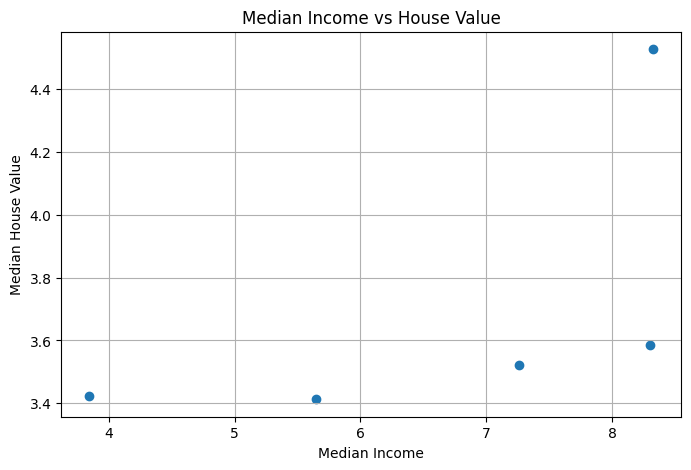

In [8]:
plt.figure(figsize=(8,5))

plt.scatter(X['MedInc'], y)

plt.title("Median Income vs House Value")

plt.xlabel("Median Income")

plt.ylabel("Median House Value")

plt.grid()

plt.show()

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)

print("Testing Target:", y_test.shape)

Training Data: (4, 1)
Testing Data: (1, 1)
Training Target: (4,)
Testing Target: (1,)


In [10]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [11]:
beta_0 = model.intercept_

beta_1 = model.coef_[0]

print("Beta 0 (Intercept):", beta_0)

print("Beta 1 (Coefficient):", beta_1)

Beta 0 (Intercept): 2.4223911145264148
Beta 1 (Coefficient): 0.20710179690786656


In [12]:
y_pred = model.predict(X_test)

print("Predictions Generated Successfully!")

comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

display(comparison.head(10))

Predictions Generated Successfully!


,Actual Price,Predicted Price
0,3.585,4.141626


In [13]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)

print("Mean Squared Error:", mse)

print("Root Mean Squared Error:", rmse)

print("R2 Score:", r2)

Mean Absolute Error: 0.556625971377378
Mean Squared Error: 0.30983247201180963
Root Mean Squared Error: 0.556625971377378
R2 Score: nan


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


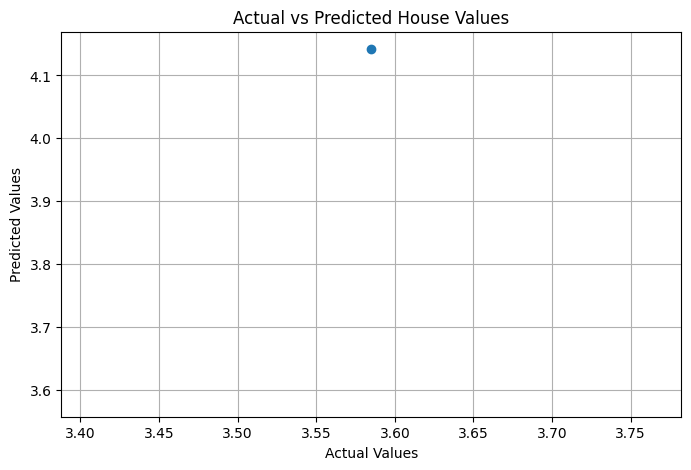

In [14]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.title("Actual vs Predicted House Values")

plt.xlabel("Actual Values")

plt.ylabel("Predicted Values")

plt.grid()

plt.show()

In [15]:
new_house = pd.DataFrame({
    'MedInc': [5.0]
})

prediction = model.predict(new_house)

print("Median Income:", 5.0)

print("Predicted House Value:", prediction[0])

print("Approximate Value in USD:", prediction[0] * 100000)

Median Income: 5.0
Predicted House Value: 3.4579000990657476
Approximate Value in USD: 345790.00990657473
